In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q -U transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 40.2 MB/s eta 0:00:00


In [ ]:
import os, re, json, string, gc
import numpy as np, pandas as pd
from tqdm.auto import tqdm

P9   = "/content/drive/MyDrive/Grad_share/data_share/P9"
OUT  = f"{P9}/goldfree_v2"; os.makedirs(OUT, exist_ok=True)

pairs = pd.read_csv(f"{P9}/p8s_behavior.csv")
HID   = np.load(f"{P9}/hid_p8s.npy")
ids   = np.load(f"{P9}/hid_p8s_ids.npy", allow_pickle=True)

print(pairs.shape, HID.shape)
print("행 정렬:", "OK" if (pairs["question"].values == ids).all() else "★불일치")
print("셀 분포:\n", pairs.groupby(["kside","ctx_label"]).size().unstack(fill_value=0))
print("behavior:", pairs.behavior.value_counts().to_dict())
print("A_cb 결측:", pairs.A_cb.isna().sum())

(1224, 19) (1224, 131072)
행 정렬: OK
셀 분포:
 ctx_label   C+   C-
kside              
K+         378  378
K−         234  234
behavior: {'accept': 880, 'retain': 201, 'other': 142, 'abstain': 1}
A_cb 결측: 0


In [ ]:
def normalize(s):
    s = str(s).lower()
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    s = "".join(ch for ch in s if ch not in string.punctuation)
    return " ".join(s.split())

def match_gold(text, golds):
    t = normalize(text)
    for g in golds:
        if not str(g).strip(): continue
        if re.search(r"\b"+re.escape(normalize(g))+r"\b", t): return True
    return False

REFUSAL_PAT = re.compile(
    r"(i (don'?t|do not) know|couldn'?t find|cannot|unable to|no information|not sure)", re.I)
REFUSAL_EXT = re.compile(
    r"(i (don'?t|do not) know|couldn'?t find|cannot|unable to|no information|not sure"
    r"|does ?n[o']?t (mention|state|specify|provide|explicitly)"
    r"|no mention of|not (mentioned|specified|stated) in)", re.I)

def layer(H, L): return H[:, (L-1)*4096:L*4096]

def diff_of_means(H, ma, mb):
    W = np.zeros((32,4096), dtype=np.float32)
    for L in range(1,33):
        HL = layer(H,L); d = HL[ma].mean(0) - HL[mb].mean(0)
        W[L-1] = d/(np.linalg.norm(d)+1e-8)
    return W

def cos_layers(A,B):
    return np.array([np.dot(A[l],B[l])/((np.linalg.norm(A[l])*np.linalg.norm(B[l]))+1e-8)
                     for l in range(32)])

def cluster_bootstrap(base, cur, groups, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed); uniq = np.unique(groups)
    idx_by_q = {q: np.where(groups==q)[0] for q in uniq}
    nets, recs, brks = [], [], []
    for _ in range(n_boot):
        rows = np.concatenate([idx_by_q[q] for q in rng.choice(uniq, len(uniq), True)])
        b,c = base[rows], cur[rows]
        r=((b==0)&(c==1)).sum(); k=((b==1)&(c==0)).sum()
        recs.append(r); brks.append(k); nets.append(r-k)
    f = lambda a: (float(np.percentile(a,2.5)), float(np.percentile(a,97.5)))
    return dict(net_mean=float(np.mean(nets)), net_CI=f(nets), rec_CI=f(recs), brk_CI=f(brks))

def em(ans, gold):
    return int(match_gold(ans, json.loads(gold) if str(gold).startswith("[") else [gold]))

print("함수 정의 완료 | em 테스트:", em("The answer is 2005.", '["2005"]'))

함수 정의 완료 | em 테스트: 1


In [ ]:
def lab_gold(r):
    ans = str(r.answer)
    golds = json.loads(r.gold) if str(r.gold).startswith("[") else [r.gold]
    if REFUSAL_PAT.search(ans):                 return "abstain"
    if match_gold(ans, [r.answer_surface]):     return "accept"
    if match_gold(ans, [r.A_cb]) or match_gold(ans, golds if r.kside=="K+" else [r.A_cb]):
        return "retain"
    return "other"

def lab_sf(r):    # A_cb만 사용 → gold 불요
    ans = str(r.answer)
    if REFUSAL_PAT.search(ans):                 return "abstain"
    if match_gold(ans, [r.answer_surface]):     return "accept"
    if match_gold(ans, [r.A_cb]):               return "retain"
    return "other"

def lab_na(r):
    ans = str(r.answer)
    if REFUSAL_PAT.search(ans):                 return "abstain"
    if match_gold(ans, [r.answer_surface]):     return "accept"
    return "retain"

def lab_na2(r):
    ans = str(r.answer)
    if REFUSAL_EXT.search(ans):                 return "abstain"
    if match_gold(ans, [r.answer_surface]):     return "accept"
    return "retain"

LABELERS = {"gold":lab_gold, "sf":lab_sf, "na":lab_na, "na2":lab_na2}
for k,f in LABELERS.items():
    pairs[f"b_{k}"] = pairs.apply(f, axis=1)

print("=== 전체 분포 ===")
for k in LABELERS:
    print(f"  {k:5}", pairs[f"b_{k}"].value_counts().to_dict())

print("\n=== gold 재현 확인 (b_gold == behavior 이어야 함) ===")
print("일치율:", (pairs.b_gold == pairs.behavior).mean())

print("\n=== gold vs sf crosstab ===")
print(pd.crosstab(pairs.b_gold, pairs.b_sf))

=== 전체 분포 ===
  gold  {'accept': 880, 'other': 174, 'retain': 169, 'abstain': 1}
  sf    {'accept': 880, 'other': 235, 'retain': 108, 'abstain': 1}
  na    {'accept': 880, 'retain': 343, 'abstain': 1}
  na2   {'accept': 740, 'abstain': 262, 'retain': 222}

=== gold 재현 확인 (b_gold == behavior 이어야 함) ===
일치율: 0.9673202614379085

=== gold vs sf crosstab ===
b_sf     abstain  accept  other  retain
b_gold                                 
abstain        1       0      0       0
accept         0     880      0       0
other          0       0    174       0
retain         0       0     61     108


In [ ]:
mm = pairs[pairs.b_gold != pairs.behavior]
print(len(mm))
print(pd.crosstab(mm.behavior, mm.b_gold))
print("\nkside/ctx:", mm.groupby(["kside","ctx_label"]).size().to_dict())
print("\n=== 불일치 8건 ===")
for _, r in mm.head(8).iterrows():
    print(f"[{r.behavior} → {r.b_gold}] kside={r.kside}")
    print("  ans :", repr(str(r.answer)[:90]))
    print("  A_cb:", repr(str(r.A_cb)[:50]), "| gold:", repr(str(r.gold)[:50]))
    print("  surf:", repr(str(r.answer_surface)[:50]))

40
b_gold    other  retain
behavior               
other         0       4
retain       36       0

kside/ctx: {('K−', 'C+'): 25, ('K−', 'C-'): 15}

=== 불일치 8건 ===
[retain → other] kside=K−
  ans : 'Actress, model, and beauty pageant titleholder.'
  A_cb: "I don't have information on Mariana Vicente's occu" | gold: '["actor", "actress", "actors", "actresses"]'
  surf: 'actor'
[retain → other] kside=K−
  ans : 'The composer of Saturday Night was Stephen Sondheim.'
  A_cb: 'The composer of "Saturday Night" is Billy Ocean.' | gold: '["Stephen Sondheim", "Stephen Joshua Sondheim"]'
  surf: 'Teddy Sinclair'
[retain → other] kside=K−
  ans : 'Football.'
  A_cb: 'Basketball' | gold: '["association football", "football", "soccer"]'
  surf: 'association football'
[retain → other] kside=K−
  ans : 'Punk'
  A_cb: 'Action' | gold: '["punk rock", "punk", "punk music"]'
  surf: 'punk rock'
[retain → other] kside=K−
  ans : 'The author of the book "Bec" is Darren Shan.'
  A_cb: 'I\'m not sure who the

In [ ]:
pairs.drop(columns=["b_gold"], inplace=True)
pairs["b_gold"] = pairs["behavior"]          # 저장본을 gold 조건으로 확정

print("=== gold(저장본) vs sf ===")
print(pd.crosstab(pairs.b_gold, pairs.b_sf))

print("\n=== retain n (평가셀 아닌 전체 학습 풀) ===")
for k in ["gold","sf","na","na2"]:
    v = pairs[f"b_{k}"].value_counts()
    print(f"  {k:5} accept {v.get('accept',0):4}  retain {v.get('retain',0):4}")

# sf가 놓친 gold-retain은 어디에 있나
lost = pairs[(pairs.b_gold=="retain") & (pairs.b_sf!="retain")]
print("\nsf가 놓친 gold-retain:", len(lost), lost.groupby(["kside","ctx_label"]).size().to_dict())
print("A_cb가 refusal 문구인 비율:", lost.A_cb.astype(str).str.contains(
    "don't have|not sure|cannot|I'm not|no information", case=False).mean().round(3))

=== gold(저장본) vs sf ===
b_sf     abstain  accept  other  retain
b_gold                                 
abstain        1       0      0       0
accept         0     880      0       0
other          0       0    138       4
retain         0       0     97     104

=== retain n (평가셀 아닌 전체 학습 풀) ===
  gold  accept  880  retain  201
  sf    accept  880  retain  108
  na    accept  880  retain  343
  na2   accept  740  retain  222

sf가 놓친 gold-retain: 97 {('K+', 'C+'): 35, ('K+', 'C-'): 26, ('K−', 'C+'): 23, ('K−', 'C-'): 13}
A_cb가 refusal 문구인 비율: 0.175


In [ ]:
from sklearn.model_selection import GroupKFold

kp_idx = pairs[(pairs.kside=="K+")&(pairs.ctx_label=="C-")].index.values
q_all  = pairs.question.values
print("평가셀 n =", len(kp_idx))          # 378

def build_oof(lab_arr, tag):
    """질문 단위 GroupKFold(5). 각 평가행은 자기 fold가 빠진 w를 받음."""
    ar = np.isin(lab_arr, ["accept","retain"])
    Wk = np.zeros((len(pairs),32,4096), dtype=np.float32)
    for tr, te in GroupKFold(5).split(np.arange(len(pairs)), groups=q_all):
        gi = tr[ar[tr]]; l = lab_arr[gi]
        assert (l=="accept").sum()>0 and (l=="retain").sum()>0, f"{tag} fold 결측"
        Wk[te] = diff_of_means(HID[gi], l=="accept", l=="retain")
    np.save(f"{OUT}/Woof_{tag}.npy", Wk[kp_idx].astype(np.float16))
    return Wk

# ── 1) 기본 4종 ──
W = {}
for k in ["gold","sf","na","na2"]:
    W[k] = build_oof(pairs[f"b_{k}"].values, k)
    v = pairs[f"b_{k}"].value_counts()
    print(f"{k:9} accept {v.get('accept',0):4} retain {v.get('retain',0):4}")

# ── 2) n-매칭 통제: gold retain을 108개로 질문단위 서브샘플 ──
N_MATCH = int((pairs.b_sf=="retain").sum())     # 108
ret_q = pairs.loc[pairs.b_gold=="retain", "question"].values
for seed in [0,1,2]:
    rng = np.random.default_rng(seed)
    ridx = np.where(pairs.b_gold.values=="retain")[0]
    keep = rng.permutation(ridx)[:N_MATCH]      # 행 단위 (질문 중복 거의 없음)
    lab = pairs.b_gold.values.copy()
    drop = np.setdiff1d(ridx, keep)
    lab[drop] = "other"                         # 학습 풀에서만 제외
    tag = f"gold_n{N_MATCH}_s{seed}"
    W[tag] = build_oof(lab, tag)
    print(f"{tag:9} accept 880 retain {(lab=='retain').sum()}")

# ── 3) 진단: gold OOF 방향과의 코사인 ──
i0 = kp_idx[0]
print("\n=== cos(W_gold, W_x) @ 평가셀 첫 샘플 ===")
for k in [x for x in W if x!="gold"]:
    c = cos_layers(W["gold"][i0], W[k][i0])
    print(f"  {k:14}", {f"L{L}": round(float(c[L-1]),3) for L in [12,14,15,16,18]})

평가셀 n = 378
gold      accept  880 retain  201
sf        accept  880 retain  108
na        accept  880 retain  343
na2       accept  740 retain  222
gold_n108_s0 accept 880 retain 108
gold_n108_s1 accept 880 retain 108
gold_n108_s2 accept 880 retain 108

=== cos(W_gold, W_x) @ 평가셀 첫 샘플 ===
  sf             {'L12': 0.876, 'L14': 0.917, 'L15': 0.929, 'L16': 0.943, 'L18': 0.946}
  na             {'L12': 0.935, 'L14': 0.928, 'L15': 0.909, 'L16': 0.916, 'L18': 0.922}
  na2            {'L12': 0.917, 'L14': 0.934, 'L15': 0.928, 'L16': 0.94, 'L18': 0.941}
  gold_n108_s0   {'L12': 0.961, 'L14': 0.973, 'L15': 0.973, 'L16': 0.976, 'L18': 0.975}
  gold_n108_s1   {'L12': 0.97, 'L14': 0.98, 'L15': 0.977, 'L16': 0.981, 'L18': 0.982}
  gold_n108_s2   {'L12': 0.967, 'L14': 0.971, 'L15': 0.968, 'L16': 0.972, 'L18': 0.963}


In [ ]:
def split_half_cos(lab_arr, n_rep=20, seed=0):
    """비겹침 절반씩으로 각각 w 추정 → 두 w의 cos. 표본노이즈만의 상한."""
    rng = np.random.default_rng(seed)
    idx = np.where(np.isin(lab_arr, ["accept","retain"]))[0]
    q = pairs.question.values[idx]; uq = np.unique(q)
    out = []
    for _ in range(n_rep):
        perm = rng.permutation(uq)
        h1 = np.isin(q, perm[:len(uq)//2])
        if not (h1.sum() and (~h1).sum()): continue
        a, b = idx[h1], idx[~h1]
        la, lb = lab_arr[a], lab_arr[b]
        if min((la=="retain").sum(), (lb=="retain").sum()) < 10: continue
        out.append(cos_layers(diff_of_means(HID[a], la=="accept", la=="retain"),
                              diff_of_means(HID[b], lb=="accept", lb=="retain")))
    return np.array(out)

print("=== split-half 노이즈 바닥 (중앙값) ===")
for k in ["gold","sf"]:
    C = split_half_cos(pairs[f"b_{k}"].values)
    print(f"  {k:5} n_rep={len(C)}", {f"L{L}": round(float(np.median(C[:,L-1])),3)
                                       for L in [12,14,15,16,18]})

# fold 평균 cos (첫 샘플 대신 5 fold 전체)
print("\n=== cos(W_gold, W_x) — 평가셀 전체 평균 ===")
sub = kp_idx[::37]   # fold 다양성 확보용 샘플
for k in ["sf","na2","gold_n108_s0"]:
    cs = np.mean([cos_layers(W["gold"][i], W[k][i]) for i in sub], axis=0)
    print(f"  {k:14}", {f"L{L}": round(float(cs[L-1]),3) for L in [12,14,15,16,18]})

=== split-half 노이즈 바닥 (중앙값) ===
  gold  n_rep=20 {'L12': 0.805, 'L14': 0.881, 'L15': 0.872, 'L16': 0.895, 'L18': 0.904}
  sf    n_rep=20 {'L12': 0.775, 'L14': 0.824, 'L15': 0.836, 'L16': 0.869, 'L18': 0.885}

=== cos(W_gold, W_x) — 평가셀 전체 평균 ===
  sf             {'L12': 0.875, 'L14': 0.902, 'L15': 0.913, 'L16': 0.928, 'L18': 0.927}
  na2            {'L12': 0.916, 'L14': 0.934, 'L15': 0.928, 'L16': 0.941, 'L18': 0.947}
  gold_n108_s0   {'L12': 0.964, 'L14': 0.973, 'L15': 0.97, 'L16': 0.973, 'L18': 0.969}


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# RAM 확보: W는 kp_idx만 디스크에서 다시 읽어 쓴다
del W; gc.collect()

MODEL_ID = "NousResearch/Meta-Llama-3.1-8B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None: tok.pad_token = tok.eos_token
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=torch.bfloat16, device_map="auto").eval()

def build_prompt_str(row):        # P9 원본과 동일
    return tok.apply_chat_template(
        [{"role":"user","content":f"{row.ctx_text}\n\nQuestion: {row.question}\nAnswer:"}],
        add_generation_prompt=True, tokenize=False)

print(repr(build_prompt_str(pairs.loc[kp_idx[0]])[-110:]))
print("GPU:", torch.cuda.get_device_name(0))

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.9k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

' of the 1974\n\nQuestion: What genre is Kanoon?\nAnswer:<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\n'
GPU: NVIDIA A100-SXM4-40GB


In [ ]:
SIGNAL = [14,15,16,17,18]          # 훅 인덱스 = 실제 decoder layer 15–19

Hk = HID[kp_idx]                   # ★ 한 번만 복사 (198MB)

# ── 1) σ: coordinate std, val Cell 28과 동일 정의 ──
sigma = np.array([layer(Hk, L).std() for L in range(1,33)], dtype=np.float32)
print("σ (L8,14,16,18):", sigma[[7,13,15,17]].round(4))

# ── 참고: projection std 환산비 (타 노트북 coef 정렬용, 실험엔 미사용) ──
w_ref = np.load(f"{OUT}/Woof_gold.npy").astype(np.float32)   # (378,32,4096)
for L in [14,16,18]:
    proj = (layer(Hk, L) * w_ref[:, L-1]).sum(1).std()       # ★ diagonal 제거
    print(f"  L{L}: coord {sigma[L-1]:.4f} / proj {proj:.4f} = {proj/sigma[L-1]:.1f}×")
del w_ref, Hk; gc.collect()

# ── 2) 훅: coef·σ·w를 미리 곱해둔 델타를 그대로 더하기만 ──
sig_np = sigma.copy()
_cfg = {"delta": None}             # (32,4096) bf16 GPU 텐서 or None(=무개입)

def make_hook(Lidx):
    def hook(mod, inp, out):
        d = _cfg["delta"]
        if d is None: return out
        if isinstance(out, tuple):
            return (out[0] + d[Lidx],) + out[1:]
        return out + d[Lidx]
    return hook

_hooks = []
def detach():
    for h in _hooks: h.remove()
    _hooks.clear()
    for lyr in model.model.layers: lyr._forward_hooks.clear()
def attach():
    detach()
    for i in SIGNAL:
        _hooks.append(model.model.layers[i].register_forward_hook(make_hook(i)))

print("훅 대상 층:", SIGNAL, "| 델타 미설정(=baseline 모드)")

σ (L8,14,16,18): [0.0692 0.1053 0.1322 0.1723]
  L14: coord 0.1053 / proj 0.7166 = 6.8×
  L16: coord 0.1322 / proj 1.0558 = 8.0×
  L18: coord 0.1723 / proj 1.5944 = 9.3×
훅 대상 층: [14, 15, 16, 17, 18] | 델타 미설정(=baseline 모드)


In [ ]:
try:
    base = np.load(f"{P9}/retain_oof.npz")["0"]
    assert len(base) == len(kp_idx)
    print(f"기존 baseline 재사용: EM {base.mean():.3f}  n={len(base)}")   # 0.458 기대
except Exception as e:
    print("재생성 필요:", e)
    detach()
    _cfg["coef"] = 0.0
    ems = []
    for i in tqdm(kp_idx, desc="baseline"):
        r = pairs.loc[i]
        enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        ems.append(em(tok.decode(g[0,L:], skip_special_tokens=True).strip(), r.gold))
    base = np.array(ems); np.save(f"{OUT}/base.npy", base)
    print(f"baseline EM {base.mean():.3f}")

기존 baseline 재사용: EM 0.458  n=378


In [ ]:
COEF  = -3.0
CONDS = ["sf", "na2", "gold_n108_s0", "gold_n108_s1", "gold_n108_s2"]
CKPT  = f"{OUT}/steer_ckpt.npz"
res = dict(np.load(CKPT)) if os.path.exists(CKPT) else {}
print("이미 완료:", list(res.keys()))

@torch.no_grad()
def run_cond(tag):
    Wk = np.load(f"{OUT}/Woof_{tag}.npy").astype(np.float32)      # (378,32,4096)
    Wk *= COEF * sig_np[None, :, None]                            # 스케일 선반영
    Wg = torch.from_numpy(Wk).to(model.device, torch.bfloat16)    # 99MB, 1회 전송
    del Wk; gc.collect()

    attach()
    ems, raws = [], []
    for j, i in enumerate(tqdm(kp_idx, desc=tag, leave=False)):
        r = pairs.loc[i]
        _cfg["delta"] = Wg[j]                                     # 뷰 참조, 복사 없음
        enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        txt = tok.decode(g[0, L:], skip_special_tokens=True).strip()
        raws.append(txt); ems.append(em(txt, r.gold))
    _cfg["delta"] = None; detach()
    del Wg; torch.cuda.empty_cache()

    pd.DataFrame({"idx": kp_idx, "text": raws}).to_csv(f"{OUT}/raw_{tag}.csv", index=False)
    return np.array(ems, dtype=int)

for tag in CONDS:
    if tag in res: continue
    res[tag] = run_cond(tag)
    np.savez(CKPT, **res)
    r = res[tag]
    rec = ((base==0)&(r==1)).sum(); brk = ((base==1)&(r==0)).sum()
    print(f"[{tag}] EM {r.mean():.3f}  회복 {rec} 손상 {brk} 순증 {rec-brk:+}")

이미 완료: []


sf:   0%|          | 0/378 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[sf] EM 0.500  회복 44 손상 28 순증 +16


na2:   0%|          | 0/378 [00:00<?, ?it/s]

...

[gold_n108_s0] EM 0.492  회복 48 손상 35 순증 +13


gold_n108_s1:   0%|          | 0/378 [00:00<?, ?it/s]

[gold_n108_s1] EM 0.484  회복 46 손상 36 순증 +10


gold_n108_s2:   0%|          | 0/378 [00:00<?, ?it/s]

[gold_n108_s2] EM 0.524  회복 48 손상 23 순증 +25


In [ ]:
g_ret = pairs.loc[kp_idx, "question"].values
print(f"baseline EM {base.mean():.3f}  n={len(base)}\n")
print(f"{'조건':16} {'retain n':>9} {'EM':>7} {'회복':>5} {'손상':>5} {'순증':>6} {'95% CI':>16}  판정")
print(f"{'gold (기록)':16} {201:>9} {0.511:>7.3f} {48:>5} {28:>5} {'+20':>6} {'[4, 37]':>16}  유의(+)")
for tag in CONDS:
    if tag not in res: continue
    cur = res[tag]
    n_ret = int((pairs[f"b_{tag.split('_s')[0] if 'gold_n' in tag else tag}"]=="retain").sum()) if tag in ["sf","na2"] else 108
    rec=((base==0)&(cur==1)).sum(); brk=((base==1)&(cur==0)).sum()
    cb = cluster_bootstrap(base, cur, g_ret)
    sig = "유의(+)" if cb["net_CI"][0]>0 else ("유의(−)" if cb["net_CI"][1]<0 else "불명확")
    print(f"{tag:16} {n_ret:>9} {cur.mean():>7.3f} {rec:>5} {brk:>5} {rec-brk:>+6} "
          f"{str([round(x) for x in cb['net_CI']]):>16}  {sig}")

baseline EM 0.458  n=378

조건                retain n      EM    회복    손상     순증           95% CI  판정
gold (기록)              201   0.511    48    28    +20          [4, 37]  유의(+)
sf                     108   0.500    44    28    +16          [0, 32]  불명확
na2                    222   0.439    34    41     -7        [-23, 10]  불명확
gold_n108_s0           108   0.492    48    35    +13         [-4, 31]  불명확
gold_n108_s1           108   0.484    46    36    +10         [-7, 27]  불명확
gold_n108_s2           108   0.524    48    23    +25          [9, 41]  유의(+)


In [ ]:
def paired_net(base, A, B, groups, n_boot=2000, seed=0):
    """net(A) − net(B)의 질문단위 클러스터 부트스트랩 CI"""
    rng = np.random.default_rng(seed); uniq = np.unique(groups)
    idx_by_q = {q: np.where(groups==q)[0] for q in uniq}
    d = []
    for _ in range(n_boot):
        rows = np.concatenate([idx_by_q[q] for q in rng.choice(uniq, len(uniq), True)])
        b = base[rows]
        na = ((b==0)&(A[rows]==1)).sum() - ((b==1)&(A[rows]==0)).sum()
        nb = ((b==0)&(B[rows]==1)).sum() - ((b==1)&(B[rows]==0)).sum()
        d.append(na-nb)
    return float(np.mean(d)), (float(np.percentile(d,2.5)), float(np.percentile(d,97.5)))

g_ret = pairs.loc[kp_idx, "question"].values
gm = np.stack([res[f"gold_n108_s{s}"] for s in [0,1,2]])   # 시드 평균용

print("=== 짝지은 차이 (양수 = 앞이 우세) ===")
for A, B in [("sf","na2"), ("sf","gold_n108_s0"), ("sf","gold_n108_s1"), ("sf","gold_n108_s2")]:
    m, ci = paired_net(base, res[A], res[B], g_ret)
    verd = "다름" if (ci[0]>0 or ci[1]<0) else "구별불가"
    print(f"  {A:6} − {B:14} {m:+6.1f}  CI[{ci[0]:.0f}, {ci[1]:.0f}]  → {verd}")

=== 짝지은 차이 (양수 = 앞이 우세) ===
  sf     − na2             +22.9  CI[9, 38]  → 다름
  sf     − gold_n108_s0     +2.9  CI[-7, 14]  → 구별불가
  sf     − gold_n108_s1     +5.7  CI[-7, 19]  → 구별불가
  sf     − gold_n108_s2     -9.0  CI[-22, 4]  → 구별불가


In [ ]:
def audit(tag):
    t = pd.read_csv(f"{OUT}/raw_{tag}.csv").text.astype(str)
    return dict(빈문자=int((t.str.strip()=="").sum()),
                길이중앙=int(t.str.len().median()),
                반복=int(t.str.contains(r"(\b\w+\b)(\s+\1){3,}", regex=True).sum()),
                거절=int(t.str.contains("don't know|cannot|not sure|no information", case=False).sum()))
for tag in CONDS: print(f"{tag:14}", audit(tag))

sf             {'빈문자': 0, '길이중앙': 201, '반복': 0, '거절': 2}
na2            {'빈문자': 0, '길이중앙': 199, '반복': 0, '거절': 2}
gold_n108_s0   {'빈문자': 0, '길이중앙': 201, '반복': 0, '거절': 3}
gold_n108_s1   {'빈문자': 0, '길이중앙': 201, '반복': 0, '거절': 1}
gold_n108_s2   {'빈문자': 0, '길이중앙': 198, '반복': 0, '거절': 2}


/tmp/ipykernel_4399/3305271162.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  반복=int(t.str.contains(r"(\b\w+\b)(\s+\1){3,}", regex=True).sum()),
/tmp/ipykernel_4399/3305271162.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  반복=int(t.str.contains(r"(\b\w+\b)(\s+\1){3,}", regex=True).sum()),
/tmp/ipykernel_4399/3305271162.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  반복=int(t.str.contains(r"(\b\w+\b)(\s+\1){3,}", regex=True).sum()),
/tmp/ipykernel_4399/3305271162.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  반복=int(t.str.contains(r"(\b\w+\b)(\s+\1){3,}", regex=True).sum()),
/tmp/ipykernel_4399/3305271162.py:5: UserWar

In [ ]:
for tag in ["sf","na2","na"]:
    r = pairs[pairs[f"b_{tag}"]=="retain"]
    print(f"{tag:4} retain n={len(r):4} | gold 기준 구성:", r.b_gold.value_counts().to_dict())

sf   retain n= 108 | gold 기준 구성: {'retain': 104, 'other': 4}
na2  retain n= 222 | gold 기준 구성: {'retain': 144, 'other': 78}
na   retain n= 343 | gold 기준 구성: {'retain': 201, 'other': 142}


gold free 더 자세하게


In [ ]:
base_sf = np.load(f"{OUT}/Woof_sf.npy").astype(np.float32).mean(0)   # 현재 균형풀 기준

def pool_w(mask, name):
    lab = pairs.b_sf.values.copy(); lab[~mask] = "drop"
    ar = np.isin(lab, ["accept","retain"])
    if (lab[ar]=="retain").sum() < 15: print(f"{name:20} 표본부족"); return
    W = diff_of_means(HID[ar], lab[ar]=="accept", lab[ar]=="retain")
    c = cos_layers(base_sf, W)
    print(f"{name:20} n={ar.sum():4} ret={(lab[ar]=='retain').sum():3} "
          f"cos: " + " ".join(f"L{L} {c[L-1]:.3f}" for L in [14,16,18]))

n = len(pairs); K = pairs.kside.values; C = pairs.ctx_label.values
pool_w(np.ones(n,bool),            "균형풀(현재)")
pool_w(K=="K+",                    "K+만")
pool_w(K=="K−",                    "K−만")
pool_w(C=="C-",                    "C−만")
pool_w(C=="C+",                    "C+만")
rng = np.random.default_rng(0)
for frac, nm in [(0.5,"랜덤 50%"), (0.25,"랜덤 25%")]:
    pool_w(rng.random(n) < frac, nm)

# K− 비중을 키운 편향풀 (자연 스트림에서 K−가 많은 경우 모사)
m = (K=="K−") | (rng.random(n) < 0.3)
pool_w(m, "K− 편중(70/30)")

균형풀(현재)              n= 988 ret=108 cos: L14 1.000 L16 1.000 L18 1.000
K+만                  n= 616 ret=104 cos: L14 0.954 L16 0.972 L18 0.978
K−만                  표본부족
C−만                  n= 493 ret= 81 cos: L14 0.960 L16 0.938 L18 0.946
C+만                  n= 495 ret= 27 cos: L14 0.853 L16 0.850 L18 0.845
랜덤 50%               n= 480 ret= 55 cos: L14 0.968 L16 0.975 L18 0.979
랜덤 25%               n= 267 ret= 28 cos: L14 0.866 L16 0.900 L18 0.909
K− 편중(70/30)         n= 558 ret= 35 cos: L14 0.950 L16 0.959 L18 0.959


In [ ]:
import re as _re
META = _re.compile(r"\b(the|this)\s+(text|passage|context|article|document|provided|excerpt)\b", _re.I)
HEDGE = _re.compile(r"(does ?n[o']?t (mention|state|specify|provide|say)|no (mention|information)"
                    r"|not (mentioned|specified|stated|clear)|unclear|however|but it)", _re.I)

na_ret = pairs[pairs.b_na=="retain"]
bad  = na_ret[na_ret.b_gold=="other"]      # 오염 142
good = na_ret[na_ret.b_gold=="retain"]     # 정상 201

def prof(df, nm):
    t = df.answer.astype(str)
    cp = np.array([str(a)[:35].lower() in str(c).lower() for a,c in zip(t, df.ctx_text)])
    print(f"{nm:5} n={len(df):3} | 메타 {t.str.contains(META).mean():.2f} "
          f"| 헤지 {t.str.contains(HEDGE).mean():.2f} | 문맥복사 {cp.mean():.2f} "
          f"| 길이중앙 {int(t.str.len().median()):3} | 30자미만 {(t.str.len()<30).mean():.2f}")
prof(bad,"오염"); prof(good,"정상")

print("\n=== 오염 예시 12개 ===")
for a in bad.answer.sample(12, random_state=0): print("  •", repr(str(a)[:85]))

오염    n=142 | 메타 0.49 | 헤지 0.51 | 문맥복사 0.24 | 길이중앙 155 | 30자미만 0.25
정상    n=201 | 메타 0.35 | 헤지 0.24 | 문맥복사 0.15 | 길이중앙  52 | 30자미만 0.39

=== 오염 예시 12개 ===
  • 'Unfortunately, the question does not provide information about the screenwriter for T'
  • 'The detective genre.'
  • "The question doesn't specify the year, but based on the text, The Players Championshi"
  • 'The text does not explicitly state the religion of Francesco Bonifacio, but based on '
  • 'The correct answer is: Comedy.\n\nHowever, according to the text, the genre of "The Big'
  • 'Ang Manila ay ang kabesera ng Pilipinas.'
  • "The text doesn't mention a country where Tigra is. It appears to be a story about a c"
  • 'The director of the film "Submission" was Jarl.'
  • 'Writer'
  • 'The text does not mention the city where Benny Napoleon was born. It only mentions th'
  • "The question doesn't mention the name of the screenwriter for Toy Story. However, it "
  • 'The text does not mention the screenwriter for La Col

/tmp/ipykernel_4399/4006681674.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  print(f"{nm:5} n={len(df):3} | 메타 {t.str.contains(META).mean():.2f} "
/tmp/ipykernel_4399/4006681674.py:14: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  f"| 헤지 {t.str.contains(HEDGE).mean():.2f} | 문맥복사 {cp.mean():.2f} "
/tmp/ipykernel_4399/4006681674.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  print(f"{nm:5} n={len(df):3} | 메타 {t.str.contains(META).mean():.2f} "
/tmp/ipykernel_4399/4006681674.py:14: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  f"| 헤지 {t.str.contains(HEDGE).mean():.2f} | 문맥복사 {cp.mean():.2f} "


In [ ]:
def screen(f, name):
    lab = pairs.b_na.values.copy()
    drop = pairs.apply(f, axis=1).values & (lab=="retain")
    lab[drop] = "other"
    r = lab=="retain"
    if r.sum()==0: print(f"{name:24} 전멸"); return
    pur = (pairs.b_gold.values[r]=="retain").mean()
    mark = " ★" if (pur>=0.95 and r.sum()>108) else ""
    print(f"{name:24} n={r.sum():4} 순도 {pur:.3f} 회수 {((pairs.b_gold.values=='retain')&r).sum():3}/201{mark}")

F_meta  = lambda r: bool(META.search(str(r.answer)))
F_hedge = lambda r: bool(HEDGE.search(str(r.answer)))
F_copy  = lambda r: str(r.answer)[:35].lower() in str(r.ctx_text).lower()
F_long  = lambda r: len(str(r.answer)) > 120
F_short = lambda r: len(str(r.answer)) < 12

screen(lambda r: False, "na (필터없음)")
for f, nm in [(F_meta,"메타"),(F_hedge,"헤지"),(F_copy,"문맥복사"),(F_long,"장문"),(F_short,"초단문")]:
    screen(f, f"+{nm}")
screen(lambda r: F_meta(r) or F_hedge(r), "메타+헤지")
screen(lambda r: F_meta(r) or F_hedge(r) or F_copy(r), "메타+헤지+복사")
screen(lambda r: F_meta(r) or F_hedge(r) or F_copy(r) or F_long(r), "위 3개+장문")
screen(lambda r: F_meta(r) or F_hedge(r) or F_copy(r) or F_long(r) or F_short(r), "전부")
print("\n[기준] sf n=108 순도 0.963 회수 104/201 → 순증 +16")

na (필터없음)                n= 343 순도 0.586 회수 201/201
+메타                      n= 203 순도 0.645 회수 131/201
+헤지                      n= 222 순도 0.685 회수 152/201
+문맥복사                    n= 279 순도 0.613 회수 171/201
+장문                      n= 185 순도 0.681 회수 126/201
+초단문                     n= 276 순도 0.558 회수 154/201
메타+헤지                    n= 183 순도 0.683 회수 125/201
메타+헤지+복사                 n= 119 순도 0.798 회수  95/201
위 3개+장문                  n= 112 순도 0.804 회수  90/201
전부                       n=  79 순도 0.759 회수  60/201

[기준] sf n=108 순도 0.963 회수 104/201 → 순증 +16


In [ ]:
lab = pairs.b_na.values.copy()
drop = pairs.apply(lambda r: F_meta(r) or F_hedge(r) or F_copy(r), axis=1).values & (lab=="retain")
lab[drop] = "other"
_ = build_oof(lab, "na_filt")
print("na_filt retain:", (lab=="retain").sum(),
      "순도:", (pairs.b_gold.values[lab=="retain"]=="retain").mean().round(3))

na_filt retain: 119 순도: 0.798


In [ ]:
for tag, coef in [("na_filt", -3.0)]:
    k = f"{tag}{coef:+}"
    if k in res2: continue
    res2[k] = run_coef(tag, coef); np.savez(CKPT2, **res2)
    cur = res2[k]; rec=((base==0)&(cur==1)).sum(); brk=((base==1)&(cur==0)).sum()
    cb = cluster_bootstrap(base, cur, g_ret)
    print(f"[{k}] EM {cur.mean():.3f} 순증 {rec-brk:+} CI[{cb['net_CI'][0]:.0f},{cb['net_CI'][1]:.0f}]")

na_filt-3.0:   0%|          | 0/378 [00:00<?, ?it/s]

[na_filt-3.0] EM 0.479 순증 +8 CI[-8,23]


In [ ]:
for A, B in [("na_filt-3.0","na2"), ("sf","na_filt-3.0")]:
    a = res2.get(A, res.get(A)); b = res2.get(B, res.get(B))
    m, ci = paired_net(base, a, b, g_ret)
    print(f"{A:14} − {B:14} {m:+6.1f} CI[{ci[0]:.0f},{ci[1]:.0f}] "
          f"→ {'다름' if (ci[0]>0 or ci[1]<0) else '구별불가'}")

na_filt-3.0    − na2             +15.0 CI[-1,31] → 구별불가
sf             − na_filt-3.0      +7.9 CI[-9,25] → 구별불가


[skip] na 미측정


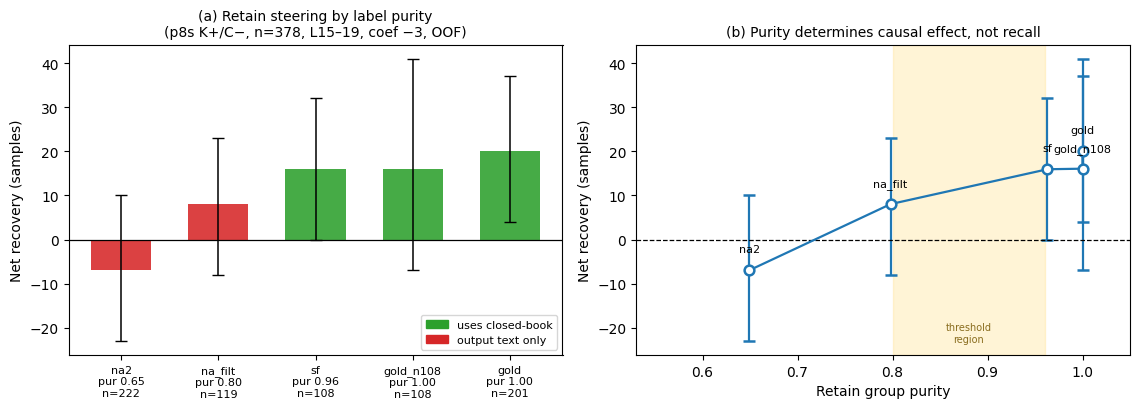

저장: /content/drive/MyDrive/Grad_share/data_share/P9/goldfree_v2/figs/fig_purity.png


In [ ]:
import matplotlib.pyplot as plt
FIG = f"{OUT}/figs"; os.makedirs(FIG, exist_ok=True)

# ── 조건 정의: (표시명, 결과배열, 순도, n, closed-book 사용) ──
def get(k):
    return res.get(k, res2.get(k))

SPEC = [
    ("na",        get("na-3.0"),          0.586, 343, False),
    ("na2",       res.get("na2"),         0.649, 222, False),
    ("na_filt",   get("na_filt-3.0"),     0.798, 119, False),
    ("sf",        res.get("sf"),          0.963, 108, True ),
    ("gold_n108", res.get("gold_n108_s0"),1.000, 108, True ),
    ("gold",      None,                   1.000, 201, True ),   # 기록값 +20 [4,37]
]

rows = []
for nm, arr, pur, n, cb_used in SPEC:
    if nm == "gold":
        rows.append((nm, 20.0, (4,37), pur, n, cb_used)); continue
    if arr is None:
        print(f"[skip] {nm} 미측정"); continue
    st = cluster_bootstrap(base, arr, g_ret)
    rows.append((nm, st["net_mean"], st["net_CI"], pur, n, cb_used))

# gold_n108은 시드 3개 평균으로 교체
seeds = [res[f"gold_n108_s{s}"] for s in [0,1,2] if f"gold_n108_s{s}" in res]
if seeds:
    ms = [cluster_bootstrap(base, a, g_ret) for a in seeds]
    i = [r[0] for r in rows].index("gold_n108")
    rows[i] = ("gold_n108", float(np.mean([m["net_mean"] for m in ms])),
               (min(m["net_CI"][0] for m in ms), max(m["net_CI"][1] for m in ms)),
               1.000, 108, True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))

# ══ (a) 조건별 순증 + CI ══
xs = np.arange(len(rows))
cols = ["#2ca02c" if r[5] else "#d62728" for r in rows]
ax1.bar(xs, [r[1] for r in rows], color=cols, width=0.62, alpha=0.88)
for i, r in enumerate(rows):
    ax1.errorbar(i, r[1], yerr=[[r[1]-r[2][0]], [r[2][1]-r[1]]],
                 color="k", capsize=4, lw=1.1)
ax1.axhline(0, c="k", lw=0.9)
ax1.set_xticks(xs)
ax1.set_xticklabels([f"{r[0]}\npur {r[3]:.2f}\nn={r[4]}" for r in rows], fontsize=8)
ax1.set_ylabel("Net recovery (samples)")
ax1.set_title("(a) Retain steering by label purity\n(p8s K+/C−, n=378, L15–19, coef −3, OOF)", fontsize=10)
from matplotlib.patches import Patch
ax1.legend(handles=[Patch(color="#2ca02c", label="uses closed-book"),
                    Patch(color="#d62728", label="output text only")], fontsize=8, loc="lower right")

# ══ (b) 순도 → 순증 (임계 관계) ══
o = sorted(rows, key=lambda r: r[3])
px, py = [r[3] for r in o], [r[1] for r in o]
lo = [r[1]-r[2][0] for r in o]; hi = [r[2][1]-r[1] for r in o]
ax2.errorbar(px, py, yerr=[lo, hi], fmt="o-", color="#1f77b4",
             capsize=4, lw=1.6, ms=7, mfc="white", mew=1.8)
for r in o:
    ax2.annotate(r[0], (r[3], r[1]), textcoords="offset points",
                 xytext=(0, 13), ha="center", fontsize=8)
ax2.axhline(0, c="k", lw=0.9, ls="--")
ax2.set_xlabel("Retain group purity"); ax2.set_ylabel("Net recovery (samples)")
ax2.set_title("(b) Purity determines causal effect, not recall", fontsize=10)
# rows에서 gold_n108_s1, s2 제외하고 s0을 시드평균으로 교체 (기존 코드에 이미 있음)
# 추가:
ax2.axvspan(0.80, 0.96, color="#ffe08a", alpha=0.35, zorder=0)
ax2.text(0.88, ax2.get_ylim()[0]+3, "threshold\nregion", ha="center", fontsize=7, color="#8a6d1f")
ax2.set_xlim(0.53, 1.05)

plt.tight_layout(); plt.savefig(f"{FIG}/fig_purity.png", dpi=150, bbox_inches="tight"); plt.show()
print("저장:", f"{FIG}/fig_purity.png")

In [ ]:
CONDS_P = [("na2", res["na2"], 0.649), ("na_filt", res2["na_filt-3.0"], 0.798),
           ("sf", res["sf"], 0.963), ("gold_n108_s0", res["gold_n108_s0"], 1.000),
           ("gold_n108_s1", res["gold_n108_s1"], 1.000), ("gold_n108_s2", res["gold_n108_s2"], 1.000)]

def trend(n_boot=2000, seed=0):
    rng = np.random.default_rng(seed); uniq = np.unique(g_ret)
    idx_by_q = {q: np.where(g_ret==q)[0] for q in uniq}
    P = np.array([p for _,_,p in CONDS_P]); slopes = []
    for _ in range(n_boot):
        rows = np.concatenate([idx_by_q[q] for q in rng.choice(uniq, len(uniq), True)])
        b = base[rows]
        nets = [((b==0)&(a[rows]==1)).sum() - ((b==1)&(a[rows]==0)).sum() for _,a,_ in CONDS_P]
        slopes.append(np.polyfit(P, nets, 1)[0])
    return float(np.mean(slopes)), (float(np.percentile(slopes,2.5)), float(np.percentile(slopes,97.5)))

m, ci = trend()
print(f"순도 기울기 {m:+.1f} 순증/순도1.0  CI[{ci[0]:.1f},{ci[1]:.1f}] "
      f"→ {'유의(+)' if ci[0]>0 else '불명확'}")

순도 기울기 +62.0 순증/순도1.0  CI[29.3,94.9] → 유의(+)


In [ ]:
_ = build_oof(pairs.b_na.values, "na")          # 이미 만들었으면 생략
res2["na-3.0"] = run_coef("na", -3.0); np.savez(CKPT2, **res2)
cur = res2["na-3.0"]
rec=((base==0)&(cur==1)).sum(); brk=((base==1)&(cur==0)).sum()
cb = cluster_bootstrap(base, cur, g_ret)
print(f"[na] EM {cur.mean():.3f} 순증 {rec-brk:+} CI[{cb['net_CI'][0]:.0f},{cb['net_CI'][1]:.0f}]")

na-3.0:   0%|          | 0/378 [00:00<?, ?it/s]

[na] EM 0.442 순증 -6 CI[-24,12]


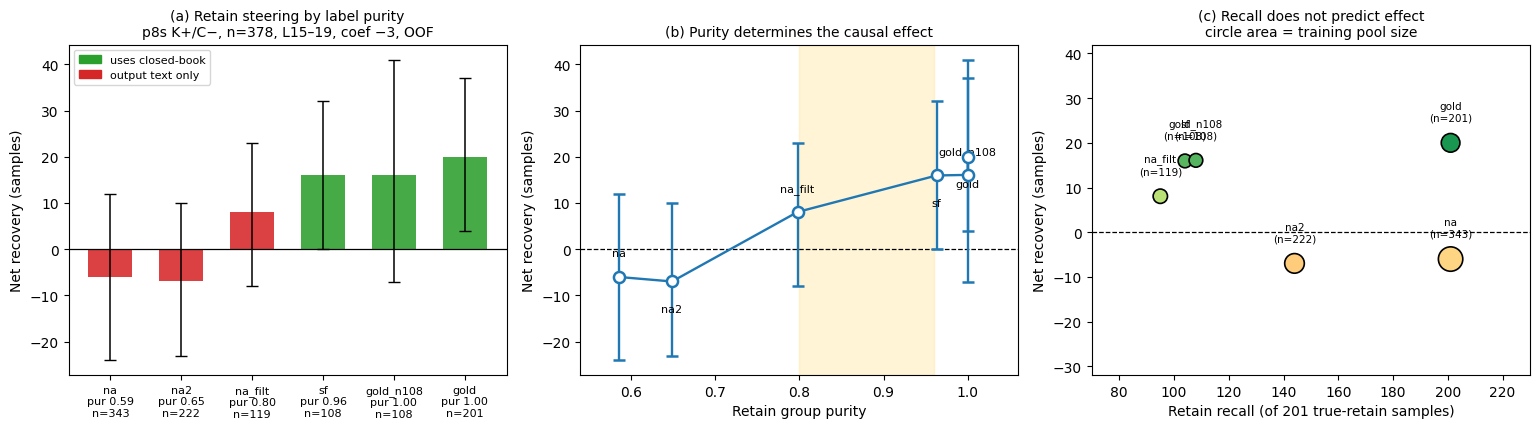

저장: /content/drive/MyDrive/Grad_share/data_share/P9/goldfree_v2/figs/fig_final_purity.png


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
FIG = f"{OUT}/figs"; os.makedirs(FIG, exist_ok=True)

def G(k): return res2.get(k, res.get(k))
gseeds = [res[f"gold_n108_s{s}"] for s in [0,1,2]]

# (name, arr, purity, n, recall, closed-book)
SPEC = [("na",       G("na-3.0"),      0.586, 343, 201, False),
        ("na2",      G("na2"),         0.649, 222, 144, False),
        ("na_filt",  G("na_filt-3.0"), 0.798, 119,  95, False),
        ("sf",       G("sf"),          0.963, 108, 104, True ),
        ("gold_n108", None,            1.000, 108, 108, True ),
        ("gold",     None,             1.000, 201, 201, True )]

R = []
for nm, a, p, n, rc, cb in SPEC:
    if nm == "gold":
        R.append(dict(nm=nm,net=20.0,ci=(4,37),rec=48,brk=28,p=p,n=n,rc=rc,cb=cb)); continue
    if nm == "gold_n108":
        ms = [cluster_bootstrap(base, x, g_ret) for x in gseeds]
        rr = np.mean([((base==0)&(x==1)).sum() for x in gseeds])
        bb = np.mean([((base==1)&(x==0)).sum() for x in gseeds])
        R.append(dict(nm=nm, net=float(np.mean([m["net_mean"] for m in ms])),
                      ci=(min(m["net_CI"][0] for m in ms), max(m["net_CI"][1] for m in ms)),
                      rec=rr, brk=bb, p=p, n=n, rc=rc, cb=cb)); continue
    st = cluster_bootstrap(base, a, g_ret)
    R.append(dict(nm=nm, net=st["net_mean"], ci=st["net_CI"],
                  rec=((base==0)&(a==1)).sum(), brk=((base==1)&(a==0)).sum(),
                  p=p, n=n, rc=rc, cb=cb))

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
GRN, RED = "#2ca02c", "#d62728"

# ══ (a) 조건별 순증 ══
ax = axes[0]; xs = np.arange(len(R))
ax.bar(xs, [r["net"] for r in R], color=[GRN if r["cb"] else RED for r in R], width=.62, alpha=.88)
for i, r in enumerate(R):
    ax.errorbar(i, r["net"], yerr=[[r["net"]-r["ci"][0]], [r["ci"][1]-r["net"]]], color="k", capsize=4, lw=1.1)
ax.axhline(0, c="k", lw=.9)
ax.set_xticks(xs); ax.set_xticklabels([f"{r['nm']}\npur {r['p']:.2f}\nn={r['n']}" for r in R], fontsize=8)
ax.set_ylabel("Net recovery (samples)")
ax.set_title("(a) Retain steering by label purity\np8s K+/C−, n=378, L15–19, coef −3, OOF", fontsize=10)
ax.legend(handles=[Patch(color=GRN, label="uses closed-book"),
                   Patch(color=RED, label="output text only")], fontsize=8, loc="upper left")

# ══ (b) 순도 → 순증 ══
ax = axes[1]; o = sorted(R, key=lambda r: (r["p"], r["n"]))
ax.axvspan(0.80, 0.96, color="#ffe08a", alpha=.35, zorder=0)
ax.errorbar([r["p"] for r in o], [r["net"] for r in o],
            yerr=[[r["net"]-r["ci"][0] for r in o], [r["ci"][1]-r["net"] for r in o]],
            fmt="o-", color="#1f77b4", capsize=4, lw=1.7, ms=8, mfc="white", mew=1.8, zorder=3)
for i, r in enumerate(o):
    ax.annotate(r["nm"], (r["p"], r["net"]), textcoords="offset points",
                xytext=(0, 15 if i % 2 == 0 else -22), ha="center", fontsize=8)
ax.axhline(0, c="k", lw=.9, ls="--")
ax.set_xlabel("Retain group purity"); ax.set_ylabel("Net recovery (samples)")
ax.set_xlim(.54, 1.06)
ax.set_title(f"(b) Purity determines the causal effect\nbootstrap slope +{m_tr:.0f} [{ci_tr[0]:.0f}, {ci_tr[1]:.0f}]"
             if "m_tr" in dir() else "(b) Purity determines the causal effect", fontsize=10)

# ══ (c) 회수량은 무관 ══
ax = axes[2]
sc = ax.scatter([r["rc"] for r in R], [r["net"] for r in R],
                s=[r["n"]*0.9 for r in R], c=[r["net"] for r in R],
                cmap="RdYlGn", vmin=-25, vmax=25, edgecolors="k", lw=1.2, zorder=3)
for r in R:
    ax.annotate(f"{r['nm']}\n(n={r['n']})", (r["rc"], r["net"]), textcoords="offset points",
                xytext=(0, 16), ha="center", fontsize=7.5)
ax.axhline(0, c="k", lw=.9, ls="--")
ax.set_xlabel("Retain recall (of 201 true-retain samples)")
ax.set_ylabel("Net recovery (samples)")
ax.set_title("(c) Recall does not predict effect\ncircle area = training pool size", fontsize=10)
ax.set_xlim(70, 230); ax.set_ylim(-32, 42)

plt.tight_layout(); plt.savefig(f"{FIG}/fig_final_purity.png", dpi=160, bbox_inches="tight"); plt.show()
print("저장:", f"{FIG}/fig_final_purity.png")

In [ ]:
CONDS_P = [("na", G("na-3.0"), 0.586), ("na2", G("na2"), 0.649),
           ("na_filt", G("na_filt-3.0"), 0.798), ("sf", G("sf"), 0.963)] + \
          [(f"g{s}", gseeds[s], 1.000) for s in range(3)]
m_tr, ci_tr = trend()
print(f"순도 기울기 {m_tr:+.1f} CI[{ci_tr[0]:.1f},{ci_tr[1]:.1f}]")

순도 기울기 +58.2 CI[34.4,82.8]


# 이후 실험

w를 데이터셋마다 따로 만들어야 하나 하나 만들어서 다 써도 되나?

In [ ]:
SV_PATH = "/content/drive/MyDrive/Grad_share/data_share/P6/strat_v2_behavior.parquet"
sv  = pd.read_parquet(SV_PATH)
HSV = np.load(f"{P9}/hid_sv_p9prompt.npy")
assert len(sv) == len(HSV), "행 수 불일치"

ACC, RET = "accepted_context", "retained_parametric"
ar_sv = sv.behavior.isin([ACC, RET]).values
q_sv  = sv.question.values
Kp    = sv.K_state3.str.startswith("K+").values

EVAL = {
  "clash":   dict(idx=np.where((sv.dataset_id=="clasheval").values & Kp)[0],
                  own=(sv.dataset_id=="clasheval").values, col="parametric_answer",  coef=-3.0),
  "confiqa": dict(idx=np.where((sv.dataset_id=="confiqa_qa").values)[0],
                  own=(sv.dataset_id=="confiqa_qa").values, col="contextual_answer", coef=+3.0),
}
for k,v in EVAL.items(): print(k, "평가 n =", len(v["idx"]))   # 222 / 480

def oof_sv(train_mask, ev_idx):
    """평가행만 (n,32,4096) 반환. 자기 fold 제외 + train_mask 교집합으로 w 추정."""
    W = np.zeros((len(sv), 32, 4096), dtype=np.float32)
    for tr, te in GroupKFold(5).split(np.arange(len(sv)), groups=q_sv):
        gi = tr[ar_sv[tr] & train_mask[tr]]
        lab = sv.behavior.values[gi]
        assert (lab==ACC).sum()>0 and (lab==RET).sum()>0
        W[te] = diff_of_means(HSV[gi], lab==ACC, lab==RET)
    out = W[ev_idx].copy(); del W; gc.collect()
    return out

rng = np.random.default_rng(0)
WSV = {}
for name, cfg in EVAL.items():
    own, ev = cfg["own"], cfg["idx"]
    n_own = int((ar_sv & own).sum())
    # 4조건
    masks = {
        "solo":    own,
        "pooled":  np.ones(len(sv), bool),
        "lodo":    ~own,
    }
    keep = rng.permutation(np.where(ar_sv)[0])[:n_own]      # 표본수 매칭
    m = np.zeros(len(sv), bool); m[keep] = True
    masks["pooledN"] = m

    for cond, mk in masks.items():
        WSV[f"{name}_{cond}"] = oof_sv(mk, ev)
        print(f"{name}_{cond:8} 학습표본 {(ar_sv & mk).sum():5}  (acc {(sv.behavior.values[ar_sv&mk]==ACC).sum()}, "
              f"ret {(sv.behavior.values[ar_sv&mk]==RET).sum()})")
        np.save(f"{OUT}/Wsv_{name}_{cond}.npy", WSV[f"{name}_{cond}"].astype(np.float16))
    del WSV[f"{name}_solo"], WSV[f"{name}_pooled"], WSV[f"{name}_lodo"], WSV[f"{name}_pooledN"]
    gc.collect()

clash 평가 n = 222
confiqa 평가 n = 480
clash_solo     학습표본   349  (acc 286, ret 63)
clash_pooled   학습표본  1169  (acc 846, ret 323)
clash_lodo     학습표본   820  (acc 560, ret 260)
clash_pooledN  학습표본   349  (acc 256, ret 93)
confiqa_solo     학습표본   256  (acc 178, ret 78)
confiqa_pooled   학습표본  1169  (acc 846, ret 323)
confiqa_lodo     학습표본   913  (acc 668, ret 245)
confiqa_pooledN  학습표본   256  (acc 174, ret 82)


In [ ]:
sig_sv = np.array([layer(HSV, L).std() for L in range(1,33)], dtype=np.float32)
print("strat_v2 σ (L8,14,16,18):", sig_sv[[7,13,15,17]].round(4))
print("p8s      σ:", sig_np[[7,13,15,17]].round(4))

def prompt_sv(r):     # val C19와 동일
    return tok.apply_chat_template(
        [{"role":"user","content":f"{r.context_trunc}\n\nQuestion: {r.question}\nAnswer:"}],
        add_generation_prompt=True, tokenize=False)

print(repr(prompt_sv(sv.iloc[EVAL["clash"]["idx"][0]])[-110:]))

strat_v2 σ (L8,14,16,18): [0.0697 0.1059 0.1325 0.1703]
p8s      σ: [0.0692 0.1053 0.1322 0.1723]
"s Phil Knight's memoir, 'Shoe Dog', released?\nAnswer:<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\n"


In [ ]:
CK3  = f"{OUT}/wcmp_ckpt.npz"
res3 = dict(np.load(CK3)) if os.path.exists(CK3) else {}
print("완료:", list(res3.keys()))

@torch.no_grad()
def run_sv(name, cond, coef):
    cfg = EVAL[name]; ev = cfg["idx"]
    Wg = None
    if coef != 0:
        Wk = np.load(f"{OUT}/Wsv_{name}_{cond}.npy").astype(np.float32) * (coef * sig_sv[None,:,None])
        Wg = torch.from_numpy(Wk).to(model.device, torch.bfloat16); del Wk; gc.collect()
    attach()
    ems, raws = [], []
    for j, i in enumerate(tqdm(ev, desc=f"{name}_{cond}{coef:+}", leave=False)):
        r = sv.iloc[i]
        _cfg["delta"] = None if Wg is None else Wg[j]
        enc = tok(prompt_sv(r), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        t = tok.decode(g[0,L:], skip_special_tokens=True).strip()
        raws.append(t); ems.append(int(match_gold(t, [r[cfg["col"]]])))
    _cfg["delta"] = None; detach()
    if Wg is not None: del Wg; torch.cuda.empty_cache()
    pd.DataFrame({"i":ev, "text":raws}).to_csv(f"{OUT}/rawsv_{name}_{cond}{coef:+}.csv", index=False)
    return np.array(ems, dtype=int)

for name, cfg in EVAL.items():
    bk = f"{name}_base"
    if bk not in res3:
        res3[bk] = run_sv(name, "solo", 0.0); np.savez(CK3, **res3)
    b = res3[bk]; gq = sv.question.values[cfg["idx"]]
    print(f"\n[{name}] baseline EM {b.mean():.3f}  n={len(b)}  coef {cfg['coef']:+}")
    for cond in ["solo","pooled","lodo","pooledN"]:
        k = f"{name}_{cond}"
        if k not in res3:
            res3[k] = run_sv(name, cond, cfg["coef"]); np.savez(CK3, **res3)
        cur = res3[k]

완료: []


clash_solo+0.0:   0%|          | 0/222 [00:00<?, ?it/s]


[clash] baseline EM 0.243  n=222  coef -3.0


clash_solo-3.0:   0%|          | 0/222 [00:00<?, ?it/s]

clash_pooled-3.0:   0%|          | 0/222 [00:00<?, ?it/s]

...


[confiqa] baseline EM 0.738  n=480  coef +3.0


confiqa_solo+3.0:   0%|          | 0/480 [00:00<?, ?it/s]

confiqa_pooled+3.0:   0%|          | 0/480 [00:00<?, ?it/s]

confiqa_lodo+3.0:   0%|          | 0/480 [00:00<?, ?it/s]

confiqa_pooledN+3.0:   0%|          | 0/480 [00:00<?, ?it/s]

In [ ]:
for name, cfg in EVAL.items():
    b = res3[f"{name}_base"]; gq = sv.question.values[cfg["idx"]]
    print(f"\n[{name}] 짝지은 차이")
    for A,B in [("pooled","solo"), ("lodo","solo"), ("lodo","pooled"), ("pooledN","solo")]:
        m, ci = paired_net(b, res3[f"{name}_{A}"], res3[f"{name}_{B}"], gq)
        print(f"  {A:8} − {B:8} {m:+6.1f} CI[{ci[0]:.0f},{ci[1]:.0f}] "
              f"→ {'다름' if (ci[0]>0 or ci[1]<0) else '구별불가'}")


[clash] 짝지은 차이
  pooled   − solo       +6.0 CI[-1,14] → 구별불가
  lodo     − solo       +5.9 CI[-2,14] → 구별불가
  lodo     − pooled     -0.1 CI[-5,5] → 구별불가
  pooledN  − solo       +2.0 CI[-5,9] → 구별불가

[confiqa] 짝지은 차이
  pooled   − solo      -10.2 CI[-24,3] → 구별불가
  lodo     − solo      -16.2 CI[-30,-1] → 다름
  lodo     − pooled     -6.0 CI[-15,3] → 구별불가
  pooledN  − solo       -9.1 CI[-23,5] → 구별불가


In [ ]:
for name, cfg in EVAL.items():
    b = res3[f"{name}_base"]; gq = sv.question.values[cfg["idx"]]
    print(f"\n[{name}] baseline EM {b.mean():.3f} n={len(b)} coef {cfg['coef']:+}")
    for cond in ["solo","pooled","lodo","pooledN"]:
        cur = res3[f"{name}_{cond}"]
        rec=((b==0)&(cur==1)).sum(); brk=((b==1)&(cur==0)).sum()
        cb = cluster_bootstrap(b, cur, gq)
        sig = "유의(+)" if cb["net_CI"][0]>0 else ("유의(−)" if cb["net_CI"][1]<0 else "불명확")
        print(f"  {cond:8} EM {cur.mean():.3f} 순증 {rec-brk:+4} "
              f"CI[{cb['net_CI'][0]:.0f},{cb['net_CI'][1]:.0f}] {sig}")


[clash] baseline EM 0.243 n=222 coef -3.0
  solo     EM 0.257 순증   +3 CI[-6,12] 불명확
  pooled   EM 0.284 순증   +9 CI[-1,19] 불명확
  lodo     EM 0.284 순증   +9 CI[-1,19] 불명확
  pooledN  EM 0.266 순증   +5 CI[-6,15] 불명확

[confiqa] baseline EM 0.738 n=480 coef +3.0
  solo     EM 0.735 순증   -1 CI[-16,15] 불명확
  pooled   EM 0.715 순증  -11 CI[-28,6] 불명확
  lodo     EM 0.702 순증  -17 CI[-34,1] 불명확
  pooledN  EM 0.717 순증  -10 CI[-26,7] 불명확


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

def oof_sv_seed(train_mask, ev_idx, seed):
    """질문 그룹을 섞은 뒤 5분할. seed마다 다른 파티션."""
    W = np.zeros((len(sv), 32, 4096), dtype=np.float32)
    uq = np.unique(q_sv); rng = np.random.default_rng(seed)
    fold = dict(zip(rng.permutation(uq), np.arange(len(uq)) % 5))
    f_of = np.array([fold[x] for x in q_sv])
    for k in range(5):
        te = np.where(f_of==k)[0]; tr = np.where(f_of!=k)[0]
        gi = tr[ar_sv[tr] & train_mask[tr]]
        lab = sv.behavior.values[gi]
        W[te] = diff_of_means(HSV[gi], lab==ACC, lab==RET)
    out = W[ev_idx].copy(); del W; gc.collect()
    return out

# confiqa solo를 시드 3개로 재추정
for sd in [1,2,3]:
    W = oof_sv_seed(EVAL["confiqa"]["own"], EVAL["confiqa"]["idx"], sd)
    np.save(f"{OUT}/Wsv_confiqa_solo_s{sd}.npy", W.astype(np.float16))
    del W; gc.collect()
    print("seed", sd, "저장")

seed 1 저장
seed 2 저장
seed 3 저장


In [ ]:
b  = res3["confiqa_base"]
gq = sv.question.values[EVAL["confiqa"]["idx"]]

print(f"[confiqa] baseline EM {b.mean():.3f} n={len(b)}")
print(f"{'조건':12} {'EM':>7} {'순증':>6} {'95% CI':>14}")
print(f"{'val C61':12} {0.779:>7.3f} {'+20':>6} {'[2, 39]':>14}   ← 재현 대상")
print(f"{'solo (전체분할)':12} {res3['confiqa_solo'].mean():>7.3f} "
      f"{((b==0)&(res3['confiqa_solo']==1)).sum()-((b==1)&(res3['confiqa_solo']==0)).sum():>+6}")

for sd in [1,2,3]:
    k = f"confiqa_solo_s{sd}"
    if k in res3: continue
    res3[k] = run_sv("confiqa", f"solo_s{sd}", +3.0); np.savez(CK3, **res3)
    cur = res3[k]
    rec=((b==0)&(cur==1)).sum(); brk=((b==1)&(cur==0)).sum()
    cb = cluster_bootstrap(b, cur, gq)
    print(f"  seed{sd:<7} {cur.mean():>7.3f} {rec-brk:>+6} "
          f"[{cb['net_CI'][0]:.0f}, {cb['net_CI'][1]:.0f}]")

[confiqa] baseline EM 0.738 n=480
조건                EM     순증         95% CI
val C61        0.779    +20        [2, 39]   ← 재현 대상
solo (전체분할)    0.735     -1


confiqa_solo_s1+3.0:   0%|          | 0/480 [00:00<?, ?it/s]

  seed1         0.738     +0 [-15, 15]


confiqa_solo_s2+3.0:   0%|          | 0/480 [00:00<?, ?it/s]

  seed2         0.738     +0 [-15, 15]


confiqa_solo_s3+3.0:   0%|          | 0/480 [00:00<?, ?it/s]

  seed3         0.742     +2 [-13, 17]


In [ ]:
a1, a2, a3 = res3["confiqa_solo_s1"], res3["confiqa_solo_s2"], res3["confiqa_solo_s3"]
print("s1==s2:", (a1==a2).all(), "| s1==s3:", (a1==a3).all())
print("baseline과 동일:", (a1==b).all())

# w가 실제로 다른가
ev = EVAL["confiqa"]["idx"]
Ws = {sd: np.load(f"{OUT}/Wsv_confiqa_solo_s{sd}.npy").astype(np.float32) for sd in [1,2,3]}
for sd in [2,3]:
    c = cos_layers(Ws[1][0], Ws[sd][0])
    print(f"cos(w_s1, w_s{sd}) L16: {c[15]:.4f}")

s1==s2: False | s1==s3: False
baseline과 동일: False
cos(w_s1, w_s2) L16: 0.9854
cos(w_s1, w_s3) L16: 0.9865


In [ ]:
def build_oof_seed(lab_arr, tag, seed):
    """질문 그룹 셔플 후 5분할."""
    ar = np.isin(lab_arr, ["accept","retain"])
    uq = np.unique(q_all); rng = np.random.default_rng(seed)
    fmap = dict(zip(rng.permutation(uq), np.arange(len(uq)) % 5))
    f_of = np.array([fmap[x] for x in q_all])
    Wk = np.zeros((len(pairs),32,4096), dtype=np.float32)
    for k in range(5):
        te = np.where(f_of==k)[0]; tr = np.where(f_of!=k)[0]
        gi = tr[ar[tr]]; l = lab_arr[gi]
        Wk[te] = diff_of_means(HID[gi], l=="accept", l=="retain")
    np.save(f"{OUT}/Woof_{tag}.npy", Wk[kp_idx].astype(np.float16))
    del Wk; gc.collect()

for sd in [1,2,3]:
    build_oof_seed(pairs.b_gold.values, f"gold_s{sd}", sd)
    build_oof_seed(pairs.b_sf.values,   f"sf_s{sd}",   sd)
    print("seed", sd, "완료")

seed 1 완료
seed 2 완료
seed 3 완료


In [ ]:
for sd in [1,2,3]:
    for tag in [f"gold_s{sd}", f"sf_s{sd}"]:
        k = f"{tag}-3.0"
        if k in res2: continue
        res2[k] = run_coef(tag, -3.0); np.savez(CKPT2, **res2)
        cur = res2[k]
        rec=((base==0)&(cur==1)).sum(); brk=((base==1)&(cur==0)).sum()
        cb = cluster_bootstrap(base, cur, g_ret)
        print(f"[{tag}] EM {cur.mean():.3f} 순증 {rec-brk:+4} "
              f"CI[{cb['net_CI'][0]:.0f},{cb['net_CI'][1]:.0f}]")

gold_s1-3.0:   0%|          | 0/378 [00:00<?, ?it/s]

[gold_s1] EM 0.503 순증  +17 CI[1,33]


sf_s1-3.0:   0%|          | 0/378 [00:00<?, ?it/s]

[sf_s1] EM 0.500 순증  +16 CI[0,32]


gold_s2-3.0:   0%|          | 0/378 [00:00<?, ?it/s]

...

[sf_s2] EM 0.489 순증  +12 CI[-4,29]


gold_s3-3.0:   0%|          | 0/378 [00:00<?, ?it/s]

[gold_s3] EM 0.484 순증  +10 CI[-6,27]


sf_s3-3.0:   0%|          | 0/378 [00:00<?, ?it/s]

[sf_s3] EM 0.503 순증  +17 CI[1,33]


In [ ]:
print("시드별 sf − gold 짝지은 차이")
for sd in ["", "_s1", "_s2", "_s3"]:
    A = res2.get(f"sf{sd}-3.0", res.get("sf"))
    B = res2.get(f"gold{sd}-3.0")
    if B is None: continue
    m, ci = paired_net(base, A, B, g_ret)
    print(f"  {sd or '원본':6} {m:+6.1f} CI[{ci[0]:.0f},{ci[1]:.0f}] "
          f"→ {'다름' if (ci[0]>0 or ci[1]<0) else '구별불가'}")

시드별 sf − gold 짝지은 차이
  _s1      -1.2 CI[-13,11] → 구별불가
  _s2      -7.0 CI[-20,5] → 구별불가
  _s3      +7.0 CI[-4,18] → 구별불가
